In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import joblib

#Load Dataset

In [3]:
df=pd.read_csv('/content/sales_analysis_dataset.csv')
print("Dataset Loaded Successfully! Shape:", df.shape)

Dataset Loaded Successfully! Shape: (1500, 16)


#Data Cleaning & Feature Engineering

In [4]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
max_date = df['Order_Date'].max()

#RFM Analysis

In [5]:
customer_df = df.groupby(['Customer_ID', 'Customer_Name']).agg(
    Recency=('Order_Date', lambda x: (max_date - x.max()).days),
    Frequency=('Order_ID', 'nunique'),
    Monetary=('Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

In [6]:
features = ['Recency', 'Frequency', 'Monetary', 'Total_Quantity']
X = customer_df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#K-Means Clustering

In [7]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
customer_df['Cluster'] = kmeans.fit_predict(X_scaled)

#Map Segment Names

In [8]:
segment_map = {
    3: 'Champions (High Value, High Freq)',
    0: 'Loyal Customers',
    2: 'Recent / Low Engagement',
    1: 'At-Risk / Inactive'
}
customer_df['Segment'] = customer_df['Cluster'].map(segment_map)

#Export Model

In [9]:
joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Model and Scaler exported successfully as .pkl files!")

Model and Scaler exported successfully as .pkl files!


#Visualize Segements

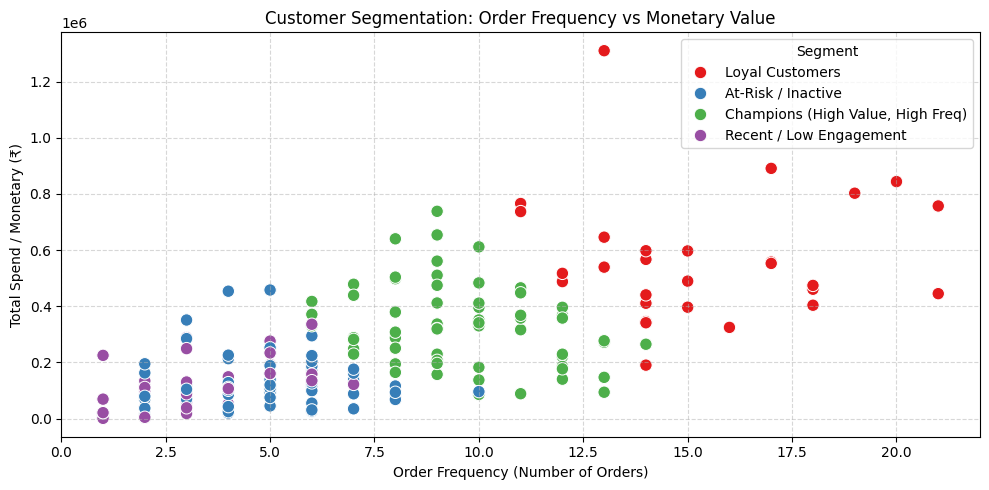

In [10]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=customer_df, x='Frequency', y='Monetary', hue='Segment', palette='Set1', s=80)
plt.title('Customer Segmentation: Order Frequency vs Monetary Value')
plt.xlabel('Order Frequency (Number of Orders)')
plt.ylabel('Total Spend / Monetary (₹)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('customer_segmentation_plot.png')
plt.show()

#Display cluster counts

In [11]:
print("\nCustomer Count per Segment:")
print(customer_df['Segment'].value_counts())


Customer Count per Segment:
Segment
At-Risk / Inactive                   70
Champions (High Value, High Freq)    65
Recent / Low Engagement              34
Loyal Customers                      28
Name: count, dtype: int64
